# Actividad 17. Benchmark Las Vegas vs. Monte Carlo

**Materia:** Lenguajes y Computación

## Equipo

| Nombre completo | No. de cuenta |
|---|---|
| Jonathan Hernández Lazcano | 200417 |
| Camila Rodriguez Rosas | 194100 |

## Descripción

**Opción B: Teoría de números / Criptografía**

| Paradigma | Algoritmo | Garantía |
|---|---|---|
| **Las Vegas** | Factorización exacta: rho de Pollard aleatorizado + certificación por división de prueba | La respuesta **siempre** es correcta; el **tiempo** es una variable aleatoria |
| **Monte Carlo** | Test de primalidad de Miller-Rabin con `k` rondas | El **tiempo** está acotado (O(k·log³n)); la respuesta puede ser errónea con probabilidad ≤ 4⁻ᵏ |

**Tarea común del benchmark:** dado un entero `n`, decidir si es primo.

* Las Vegas lo decide factorizando `n` por completo (`n` es primo ⇔ su factorización tiene un solo factor).
* Monte Carlo lo decide con `k` rondas independientes de Miller-Rabin.

**Contenido:** 1) Implementación · 2) Suite de pruebas · 3) Benchmark de tiempo y memoria vs N · 4) Variabilidad del tiempo Las Vegas · 5) Error vs número de rondas k (amplificación del éxito) · 6) Tabla comparativa · 7) Análisis y conclusión

In [1]:
# Importaciones
import math
import random
import time
import tracemalloc
import unittest

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA_GLOBAL = 2026          # semilla base para que el benchmark sea reproducible
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Implementación

### 1.1 Las Vegas: factorización exacta

El algoritmo combina dos piezas:

1. **Rho de Pollard (aleatorizado).** Itera `x ← x² + c (mod m)` desde un `x₀` y una `c` **aleatorios** y usa la detección de ciclos de Floyd. Cuando `gcd(|x − y|, m)` es un divisor no trivial, separa `m` en dos factores. Si un intento falla (`gcd = m`) o se agota su presupuesto de iteraciones, se vuelve a intentar con otros `x₀` y `c`. Por eso el tiempo depende de la suerte.
2. **Certificación exacta (división de prueba).** Si rho no logra separar `m` dentro de su presupuesto, `menor_divisor(m)` prueba todos los candidatos `6i ± 1 ≤ √m`. Este paso es determinista y **nunca se equivoca**: o demuestra que `m` es primo o encuentra un divisor.

El resultado siempre es correcto (la parte aleatoria solo cambia *cuánto* se tarda) y además se verifica que `∏ factores = n`. No se usa Miller-Rabin en ningún paso de Las Vegas.

In [2]:
def menor_divisor(m: int) -> int:
    # Devuelve el menor divisor primo de m (m >= 2) por división de prueba.
    # Si m es primo devuelve el propio m. Es determinista y exacto:
    # prueba 2, 3 y luego todos los candidatos de la forma 6i ± 1 hasta √m.
    if m % 2 == 0:
        return 2
    if m % 3 == 0:
        return 3
    limite = math.isqrt(m)
    d = 5
    while d <= limite:
        if m % d == 0:
            return d
        if m % (d + 2) == 0:
            return d + 2
        d += 6
    return m


def es_primo_exacto(m: int) -> bool:
    # Primalidad exacta (determinista) basada en menor_divisor.
    return m >= 2 and menor_divisor(m) == m


def rho_pollard(m: int, rng: random.Random, intentos: int = 3) -> int | None:
    # Intenta encontrar un divisor no trivial de m (m compuesto o primo, impar).
    # - Cada intento elige x0 y c aleatorios (fuente de aleatoriedad Las Vegas).
    # - Presupuesto por intento ~ 4·m^(1/4) iteraciones: si m tiene un factor
    #   p <= √m, rho lo encuentra en O(√p) = O(m^(1/4)) pasos esperados.
    # - Devuelve el divisor encontrado o None si se agotaron los intentos
    #   (por ejemplo, porque m es primo). None NO significa "primo": la
    #   decisión final la toma siempre la certificación exacta.
    presupuesto = 4 * math.isqrt(math.isqrt(m)) + 16
    for _ in range(intentos):
        x = y = rng.randrange(2, m)
        c = rng.randrange(1, m)
        for _ in range(presupuesto):
            x = (x * x + c) % m            # tortuga: un paso
            y = (y * y + c) % m            # liebre: dos pasos
            y = (y * y + c) % m
            d = math.gcd(abs(x - y), m)
            if d == m:                     # ciclo sin éxito: reintentar con otra semilla
                break
            if d > 1:
                return d
    return None


def factorizar_lv(n: int, rng: random.Random) -> list[int]:
    # Algoritmo LAS VEGAS: factorización completa y siempre correcta de n.
    # Devuelve la lista ordenada de factores primos (con multiplicidad).
    if n < 2:
        return []
    factores, pendientes = [], [n]
    while pendientes:
        m = pendientes.pop()
        if m < 2:
            continue
        if m % 2 == 0:                     # factor 2 directo
            factores.append(2)
            pendientes.append(m // 2)
            continue
        d = rho_pollard(m, rng) if m > 1_000 else None
        if d is None:                      # rho no separó m -> certificación exacta
            d = menor_divisor(m)
            if d == m:                     # m está demostrado primo
                factores.append(m)
                continue
        pendientes.extend((d, m // d))     # separar y seguir factorizando
    factores.sort()
    assert math.prod(factores) == n, "La factorización no reconstruye n"  # garantía LV
    return factores


def es_primo_lv(n: int, rng: random.Random) -> bool:
    # Decisión de primalidad Las Vegas: n primo <=> un único factor primo.
    return len(factorizar_lv(n, rng)) == 1


rng = random.Random(1)
for n in (97, 561, 8_911, 1_000_003, 9_999_991, 2**10 * 3**4, 1_234_567):
    print(f"{n:>10,} -> {factorizar_lv(n, rng)}  primo={es_primo_lv(n, rng)}")

        97 -> [97]  primo=True
       561 -> [3, 11, 17]  primo=False
     8,911 -> [7, 19, 67]  primo=False
 1,000,003 -> [1000003]  primo=True
 9,999,991 -> [9999991]  primo=True
    82,944 -> [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3]  primo=False
 1,234,567 -> [127, 9721]  primo=False


### 1.2 Monte Carlo: test de primalidad de Miller-Rabin

Se escribe `n − 1 = d · 2ˢ` con `d` impar. Para una base aleatoria `a`, `n` **pasa la ronda** si `aᵈ ≡ 1` o `a^(d·2ʳ) ≡ −1 (mod n)` para algún `0 ≤ r < s`.

* Si `n` es **primo**, pasa todas las rondas: el error es de **un solo lado** (nunca declara compuesto a un primo).
* Si `n` es **compuesto**, a lo más ¼ de las bases son "mentirosas fuertes" (teorema de Rabin-Monier).

**Amplificación del éxito:** cada ronda es una ejecución **independiente** con una base nueva. El test solo acepta "probable primo" si **todas** las `k` rondas lo aceptan, así que

$$P(\text{error}) = \prod_{i=1}^{k} P(a_i \text{ es mentirosa}) = f_n^{\,k} \le 4^{-k}.$$

El tiempo está acotado: `k` exponenciaciones modulares, O(k · log³ n), sin importar la suerte.

In [3]:
def descomponer(n: int) -> tuple[int, int]:
    # Escribe n - 1 = d · 2^s con d impar. Devuelve (d, s).
    d, s = n - 1, 0
    while d % 2 == 0:
        d //= 2
        s += 1
    return d, s


def ronda_mr(n: int, a: int, d: int, s: int) -> bool:
    # UNA ejecución independiente de Miller-Rabin con la base a.
    # True  -> n pasa la ronda ("probable primo" para esta base).
    # False -> a es TESTIGO: n es compuesto con certeza.
    x = pow(a, d, n)
    if x == 1 or x == n - 1:
        return True
    for _ in range(s - 1):
        x = x * x % n
        if x == n - 1:
            return True
    return False


def miller_rabin(n: int, k: int, rng: random.Random) -> bool:
    # Algoritmo MONTE CARLO: k rondas con bases aleatorias en [2, n-2].
    # Devuelve True ("probable primo") solo si las k rondas lo aceptan.
    # Error de un solo lado: si devuelve False, n es compuesto con certeza.
    if n < 2:
        return False
    if n < 4:
        return True                        # 2 y 3
    if n % 2 == 0:
        return False
    d, s = descomponer(n)
    for _ in range(k):                     # amplificación por ejecuciones independientes
        if not ronda_mr(n, rng.randrange(2, n - 1), d, s):
            return False
    return True


def fraccion_mentirosos(n: int) -> float:
    # Fracción EXACTA de bases a en [2, n-2] que son mentirosas fuertes para n
    # (por fuerza bruta; solo para n pequeño). Es la probabilidad de error de
    # UNA ronda de miller_rabin, porque las bases se eligen en ese intervalo.
    d, s = descomponer(n)
    mentirosas = sum(ronda_mr(n, a, d, s) for a in range(2, n - 1))
    return mentirosas / (n - 3)


rng = random.Random(1)
for n in (97, 561, 8_911, 1_000_003, 9_999_991):
    print(f"{n:>10,}: k=1 -> {miller_rabin(n, 1, rng)}, k=20 -> {miller_rabin(n, 20, rng)}")

        97: k=1 -> True, k=20 -> True
       561: k=1 -> False, k=20 -> False
     8,911: k=1 -> False, k=20 -> False
 1,000,003: k=1 -> True, k=20 -> True
 9,999,991: k=1 -> True, k=20 -> True


## 2. Suite de pruebas

Se comparan ambos algoritmos contra una **criba de Eratóstenes** (verdad absoluta) y se prueban casos borde: `n < 2`, pares, potencias de primos, cuadrados de primos y números de Carmichael.

In [4]:
def criba(limite: int) -> np.ndarray:
    # Criba de Eratóstenes: es_primo[i] == True <=> i es primo (0 <= i < limite).
    es_primo = np.ones(limite, dtype=bool)
    es_primo[:2] = False
    for p in range(2, math.isqrt(limite - 1) + 1):
        if es_primo[p]:
            es_primo[p * p :: p] = False
    return es_primo


CARMICHAEL = [561, 1105, 1729, 2465, 2821, 6601, 8911, 10585, 15841,
              29341, 41041, 46657, 52633, 62745, 63973, 75361]


class PruebasLasVegas(unittest.TestCase):
    def setUp(self):
        self.rng = random.Random(123)

    def test_casos_borde(self):
        self.assertEqual(factorizar_lv(0, self.rng), [])
        self.assertEqual(factorizar_lv(1, self.rng), [])
        self.assertEqual(factorizar_lv(2, self.rng), [2])
        self.assertEqual(factorizar_lv(4, self.rng), [2, 2])
        self.assertFalse(es_primo_lv(1, self.rng))

    def test_potencias_y_cuadrados(self):
        self.assertEqual(factorizar_lv(3**8, self.rng), [3] * 8)
        self.assertEqual(factorizar_lv(7**4, self.rng), [7] * 4)
        self.assertEqual(factorizar_lv(3_163**2, self.rng), [3_163, 3_163])
        self.assertEqual(factorizar_lv(2**20, self.rng), [2] * 20)

    def test_factorizaciones_conocidas(self):
        self.assertEqual(factorizar_lv(561, self.rng), [3, 11, 17])
        self.assertEqual(factorizar_lv(1_234_567, self.rng), [127, 9_721])
        self.assertEqual(factorizar_lv(999_983 * 999_979, self.rng), [999_979, 999_983])

    def test_producto_reconstruye_n(self):
        for n in random.Random(7).sample(range(2, 10**9), 300):
            fs = factorizar_lv(n, self.rng)
            self.assertEqual(math.prod(fs), n)
            self.assertTrue(all(es_primo_exacto(f) for f in fs))

    def test_coincide_con_criba(self):
        primos = criba(100_000)
        for n in range(100_000):
            self.assertEqual(es_primo_lv(n, self.rng), bool(primos[n]), msg=f"n={n}")


class PruebasMonteCarlo(unittest.TestCase):
    def setUp(self):
        self.rng = random.Random(321)

    def test_casos_borde(self):
        for n, esperado in [(0, False), (1, False), (2, True), (3, True), (4, False), (5, True)]:
            self.assertEqual(miller_rabin(n, 5, self.rng), esperado, msg=f"n={n}")

    def test_nunca_rechaza_un_primo(self):
        # Error de un solo lado: incluso con k = 1 un primo nunca es rechazado.
        primos = np.flatnonzero(criba(100_000))
        for p in primos:
            self.assertTrue(miller_rabin(int(p), 1, self.rng), msg=f"p={p}")

    def test_coincide_con_criba_k20(self):
        primos = criba(100_000)
        for n in range(100_000):
            self.assertEqual(miller_rabin(n, 20, self.rng), bool(primos[n]), msg=f"n={n}")

    def test_detecta_carmichael(self):
        # Los números de Carmichael engañan a Fermat, pero no a Miller-Rabin con k = 20.
        for n in CARMICHAEL:
            self.assertFalse(miller_rabin(n, 20, self.rng), msg=f"n={n}")

    def test_cota_de_rabin(self):
        # La fracción de mentirosas fuertes nunca supera 1/4.
        for n in CARMICHAEL[:8] + [91, 703, 1891, 3277]:
            self.assertLessEqual(fraccion_mentirosos(n), 0.25)


suite = unittest.TestSuite()
for caso in (PruebasLasVegas, PruebasMonteCarlo):
    suite.addTests(unittest.defaultTestLoader.loadTestsFromTestCase(caso))
resultado_pruebas = unittest.TextTestRunner(verbosity=2).run(suite)
assert resultado_pruebas.wasSuccessful()

test_casos_borde (__main__.PruebasLasVegas.test_casos_borde) ... 

ok


test_coincide_con_criba (__main__.PruebasLasVegas.test_coincide_con_criba) ... 

ok


test_factorizaciones_conocidas (__main__.PruebasLasVegas.test_factorizaciones_conocidas) ... 

ok


... (11 outputs left out)

ok


test_nunca_rechaza_un_primo (__main__.PruebasMonteCarlo.test_nunca_rechaza_un_primo) ... 

ok


----------------------------------------------------------------------
Ran 10 tests in 1.583s

OK


## 3. Benchmark de tiempo y memoria vs. tamaño de entrada N

* **N** = tamaño del lote: cantidad de enteros impares aleatorios a clasificar, N ∈ {10², 10³, 10⁴, 10⁵}.
* Todos los enteros se toman del rango fijo **[10⁶, 10⁷)**. Así el costo por número es comparable y la certificación exacta termina en un tiempo razonable.
* Cada algoritmo se repite **R** veces con semillas distintas. El tiempo en milisegundos se mide con `time.perf_counter()`.
* Monte Carlo usa **k = 10** rondas (cota de error ≤ 4⁻¹⁰ ≈ 9.5·10⁻⁷).
* La memoria pico se mide en una ejecución aparte con `tracemalloc`, porque `tracemalloc` distorsiona los tiempos.
* El **% de error** se calcula contra la respuesta exacta de Las Vegas.

In [5]:
TAMANOS = [10**2, 10**3, 10**4, 10**5]
REPETICIONES = {10**2: 30, 10**3: 15, 10**4: 7, 10**5: 3}
K_BENCH = 10
RANGO = (10**6, 10**7)


def generar_lote(N: int, semilla: int) -> list[int]:
    # N enteros impares aleatorios en RANGO.
    r = random.Random(semilla)
    return [r.randrange(RANGO[0] + 1, RANGO[1], 2) for _ in range(N)]


def clasificar_lv(lote, semilla):
    rng = random.Random(semilla)
    return [es_primo_lv(n, rng) for n in lote]


def clasificar_mc(lote, semilla, k=K_BENCH):
    rng = random.Random(semilla)
    return [miller_rabin(n, k, rng) for n in lote]


def medir_ms(funcion, *args):
    # Ejecuta funcion(*args) y devuelve (resultado, tiempo en ms).
    t0 = time.perf_counter()
    resultado = funcion(*args)
    return resultado, (time.perf_counter() - t0) * 1_000


def memoria_pico_kib(funcion, *args):
    # Memoria pico (KiB) asignada durante funcion(*args), medida con tracemalloc.
    tracemalloc.start()
    funcion(*args)
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pico / 1024


registros = []
for N in TAMANOS:
    lote = generar_lote(N, SEMILLA_GLOBAL + N)
    for r in range(REPETICIONES[N]):
        semilla = SEMILLA_GLOBAL * 1_000 + r
        verdad, t_lv = medir_ms(clasificar_lv, lote, semilla)
        resp_mc, t_mc = medir_ms(clasificar_mc, lote, semilla)
        errores = sum(a != b for a, b in zip(verdad, resp_mc))
        registros.append({"N": N, "rep": r, "t_lv_ms": t_lv, "t_mc_ms": t_mc,
                          "errores_mc": errores, "primos": sum(verdad)})
    mem_lv = memoria_pico_kib(clasificar_lv, lote, 0)
    mem_mc = memoria_pico_kib(clasificar_mc, lote, 0)
    for reg in registros:
        if reg["N"] == N:
            reg["mem_lv_kib"], reg["mem_mc_kib"] = mem_lv, mem_mc
    print(f"N={N:>7,}: listo ({REPETICIONES[N]} repeticiones)")

df_bench = pd.DataFrame(registros)
df_bench.groupby("N")[["t_lv_ms", "t_mc_ms"]].agg(["mean", "std", "min", "max"])

N=    100: listo (30 repeticiones)


N=  1,000: listo (15 repeticiones)


N= 10,000: listo (7 repeticiones)


N=100,000: listo (3 repeticiones)


t_lv_ms                                t_mc_ms                  \
             mean     std        min        max     mean    std      min   
N                                                                          
100        4.5668  0.0947     4.3552     4.8169   0.1880 0.0067   0.1803   
1000      51.6261  0.9524    50.3870    53.8560   1.7356 0.0430   1.6525   
10000    527.6534  7.1118   520.2266   537.6120  18.8395 0.3960  18.3113   
100000 5,370.4702 17.0946 5,351.0427 5,383.2096 194.1078 2.9995 192.2009   

                 
            max  
N                
100      0.2056  
1000     1.8076  
10000   19.6002  
100000 197.5653

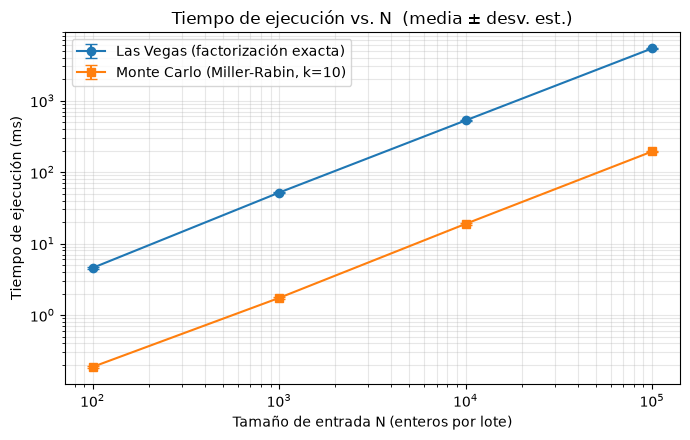

In [6]:
# Gráfica 1: tiempo de ejecución vs N
resumen = df_bench.groupby("N").agg(lv_media=("t_lv_ms", "mean"), lv_std=("t_lv_ms", "std"),
                                    mc_media=("t_mc_ms", "mean"), mc_std=("t_mc_ms", "std"))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(resumen.index, resumen.lv_media, yerr=resumen.lv_std, marker="o", capsize=4,
            label="Las Vegas (factorización exacta)")
ax.errorbar(resumen.index, resumen.mc_media, yerr=resumen.mc_std, marker="s", capsize=4,
            label=f"Monte Carlo (Miller-Rabin, k={K_BENCH})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Tamaño de entrada N (enteros por lote)")
ax.set_ylabel("Tiempo de ejecución (ms)")
ax.set_title("Tiempo de ejecución vs. N  (media ± desv. est.)")
ax.grid(True, which="both", alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig("grafica_tiempo_vs_N.png", dpi=150)
plt.show()

## 4. Variabilidad del tiempo de Las Vegas como variable aleatoria

Se toma un mismo conjunto de enteros y cada uno se factoriza muchas veces con semillas distintas. La entrada no cambia, así que toda la variación en el tiempo viene de las elecciones aleatorias de rho de Pollard (`x₀` y `c`). Como comparación se mide también Miller-Rabin sobre los mismos números.

In [7]:
def tiempos_por_semilla(n: int, funcion, repeticiones: int) -> np.ndarray:
    # Tiempo (µs) de funcion(n, rng) para muchas semillas distintas, con la entrada fija.
    ts = np.empty(repeticiones)
    for i in range(repeticiones):
        rng = random.Random(i)
        t0 = time.perf_counter()
        funcion(n, rng)
        ts[i] = (time.perf_counter() - t0) * 1e6
    return ts


# Compuestos con dos factores grandes: rho debe "tener suerte" para separarlos
casos = {"1009·9973 ≈ 1.0·10⁷": 1009 * 9973,
         "31627·31643 ≈ 1.0·10⁹": 31_627 * 31_643,
         "99991·99989 ≈ 1.0·10¹⁰": 99_991 * 99_989}
REP_VAR = 2_000
filas, datos_lv = [], {}
for nombre, n in casos.items():
    t_lv = tiempos_por_semilla(n, factorizar_lv, REP_VAR)
    t_mc = tiempos_por_semilla(n, lambda m, r: miller_rabin(m, K_BENCH, r), REP_VAR)
    datos_lv[nombre] = t_lv
    filas.append({"entrada": nombre, "LV media (µs)": t_lv.mean(), "LV desv. (µs)": t_lv.std(),
                  "LV min (µs)": t_lv.min(), "LV p95 (µs)": np.percentile(t_lv, 95),
                  "LV max (µs)": t_lv.max(), "LV coef. var.": t_lv.std() / t_lv.mean(),
                  "MC media (µs)": t_mc.mean(), "MC coef. var.": t_mc.std() / t_mc.mean()})
df_var = pd.DataFrame(filas).set_index("entrada")
df_var

,LV media (µs),LV desv. (µs),LV min (µs),LV p95 (µs),LV max (µs),LV coef. var.,MC media (µs),MC coef. var.
entrada,,,,,,,,
1009·9973 ≈ 1.0·10⁷,44.5937,5.7738,27.6670,53.9190,109.2080,0.1295,1.3081,0.1281
31627·31643 ≈ 1.0·10⁹,94.8813,15.6032,58.8750,123.2911,169.1250,0.1644,1.5166,0.2038
99991·99989 ≈ 1.0·10¹⁰,197.6102,51.4923,98.2090,294.6313,445.8330,0.2606,4.3371,0.0764


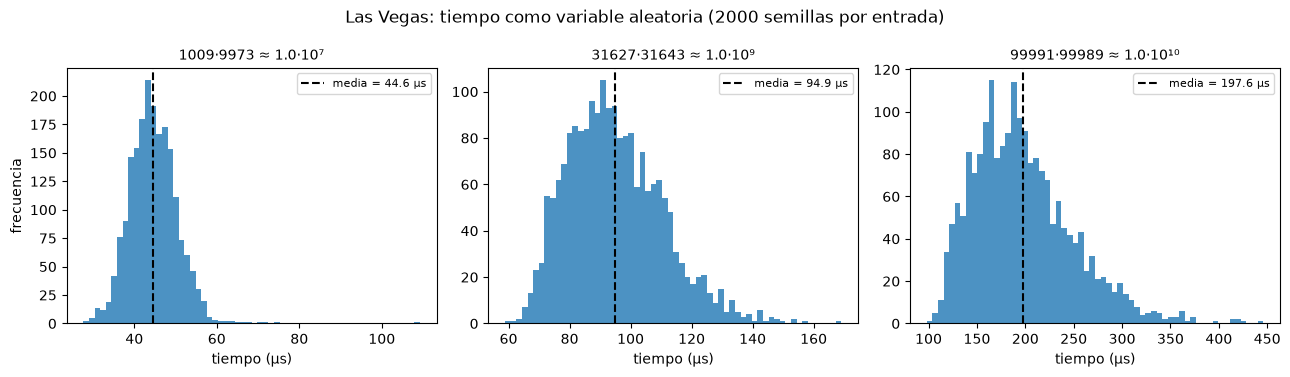

In [8]:
# Gráfica 3: distribución del tiempo Las Vegas (misma entrada, distintas semillas)
fig, axes = plt.subplots(1, len(datos_lv), figsize=(13, 3.8))
for ax, (nombre, ts) in zip(axes, datos_lv.items()):
    ax.hist(ts, bins=60, color="tab:blue", alpha=0.8)
    ax.axvline(ts.mean(), color="black", ls="--", label=f"media = {ts.mean():.1f} µs")
    ax.set_title(nombre, fontsize=10); ax.set_xlabel("tiempo (µs)"); ax.legend(fontsize=8)
axes[0].set_ylabel("frecuencia")
fig.suptitle(f"Las Vegas: tiempo como variable aleatoria ({REP_VAR} semillas por entrada)")
fig.tight_layout(); fig.savefig("grafica_variabilidad_lv.png", dpi=150)
plt.show()

## 5. Tasa de error vs. número de rondas k (amplificación del éxito)

Con enteros aleatorios Miller-Rabin casi nunca se equivoca (sección 3), así que un error no se observaría en la práctica. Para **medir** el error se usa un **conjunto difícil** de compuestos con muchas bases mentirosas:

* Números de **Carmichael** (engañan siempre al test de Fermat).
* Semiprimos de la forma **(2m+1)(4m+1)** con ambos factores primos, que se acercan a la cota ¼ de Rabin.

Para cada `n` se calcula **exactamente** (fuerza bruta) la fracción de mentirosas `fₙ`. Luego, para cada k ∈ {1, 5, 10, 20, 50}, se hacen **T** ensayos independientes de `miller_rabin(n, k)` repartidos en el conjunto. Se compara:

* **error empírico** = % de ensayos en que un compuesto fue declarado "primo";
* **error predicho** = promedio de `fₙᵏ`;
* **cota teórica** = 4⁻ᵏ.

In [9]:
# Conjunto difícil: Carmichael + semiprimos (2m+1)(4m+1)
SEMIPRIMOS = [(2*m + 1) * (4*m + 1) for m in range(2, 60)
              if es_primo_exacto(2*m + 1) and es_primo_exacto(4*m + 1)]
DIFICILES = sorted(set(CARMICHAEL[:10] + SEMIPRIMOS))
f_n = {n: fraccion_mentirosos(n) for n in DIFICILES}

df_dif = (pd.DataFrame({"n": list(f_n), "factores": [factorizar_lv(n, random.Random(0)) for n in f_n],
                        "fracción mentirosas f_n": list(f_n.values())})
          .sort_values("fracción mentirosas f_n", ascending=False).reset_index(drop=True))
df_dif

,n,factores,fracción mentirosas f_n
0,12403,"[79, 157]",0.2452
1,1891,"[31, 61]",0.2373
2,703,"[19, 37]",0.2286
3,8911,"[7, 19, 67]",0.1998
4,91,"[7, 13]",0.1818
5,2701,"[37, 73]",0.1794
6,18721,"[97, 193]",0.1643
7,29341,"[13, 37, 61]",0.1380
8,2821,"[7, 13, 31]",0.0951
9,1729,"[7, 13, 19]",0.0927


In [10]:
KS = [1, 5, 10, 20, 50]
T = 200_000                                  # ensayos independientes por cada k

filas_k = []
for k in KS:
    rng = random.Random(SEMILLA_GLOBAL + k)
    errores = 0
    t0 = time.perf_counter()
    for i in range(T):
        n = DIFICILES[i % len(DIFICILES)]    # recorrido uniforme del conjunto difícil
        if miller_rabin(n, k, rng):          # un compuesto declarado "primo" = error
            errores += 1
    t_ms = (time.perf_counter() - t0) * 1_000
    predicho = np.mean([f_n[n] ** k for n in DIFICILES])
    filas_k.append({"k": k, "ensayos": T, "errores": errores,
                    "error empírico (%)": 100 * errores / T,
                    "error predicho (%)": 100 * predicho,
                    "cota 4^-k (%)": 100 * 4.0 ** -k,
                    "tiempo total (ms)": t_ms})

# Costo de k sobre entradas típicas (lote de 10^4 enteros de [10^6, 10^7))
lote_k = generar_lote(10**4, 99)
for fila in filas_k:
    _, t = medir_ms(clasificar_mc, lote_k, 0, fila["k"])
    fila["MC lote 10⁴ (ms)"] = t

df_k = pd.DataFrame(filas_k).set_index("k")
df_k.style.format({"error empírico (%)": "{:.4g}", "error predicho (%)": "{:.4g}",
                   "cota 4^-k (%)": "{:.3e}", "tiempo total (ms)": "{:,.1f}",
                   "MC lote 10⁴ (ms)": "{:,.1f}", "ensayos": "{:,}", "errores": "{:,}"})

,ensayos,errores,error empírico (%),error predicho (%),cota 4^-k (%),tiempo total (ms),MC lote 10⁴ (ms)
k,,,,,,,
1,"200,000","24,930",12.46,12.44,2.500e+01,167.9,10.7
5,"200,000",41,0.0205,0.01969,9.766e-02,184.9,15.1
10,"200,000",0,0,1.207e-05,9.537e-05,185.8,20.5
20,"200,000",0,0,6.877e-12,9.095e-11,183.3,31.4
50,"200,000",0,0,2.274e-30,7.889e-29,182.7,64.1


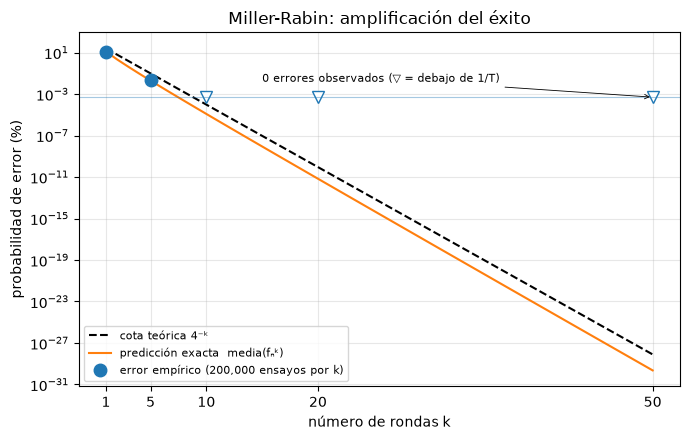

In [11]:
# Gráfica 2: probabilidad de error (%) vs k
fig, ax = plt.subplots(figsize=(7, 4.5))
ks_finos = np.arange(1, 51)
ax.plot(ks_finos, 100 * 4.0 ** -ks_finos, "k--", label="cota teórica 4⁻ᵏ")
ax.plot(ks_finos, [100 * np.mean([f_n[n] ** k for n in DIFICILES]) for k in ks_finos],
        color="tab:orange", label="predicción exacta  media(fₙᵏ)")
emp = df_k["error empírico (%)"]
positivos = emp[emp > 0]
ax.plot(positivos.index, positivos.values, "o", ms=9, color="tab:blue",
        label=f"error empírico ({T:,} ensayos por k)")
piso = 100 / T                                # resolución: 1 error en T ensayos
for k in emp[emp == 0].index:
    ax.plot(k, piso, "v", ms=9, color="tab:blue", mfc="white")
ax.axhline(piso, color="tab:blue", lw=0.8, alpha=0.4)
ax.annotate("0 errores observados (▽ = debajo de 1/T)", (KS[-1], piso), xytext=(15, piso * 30),
            fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.6))
ax.set_yscale("log"); ax.set_xticks(KS)
ax.set_xlabel("número de rondas k"); ax.set_ylabel("probabilidad de error (%)")
ax.set_title("Miller-Rabin: amplificación del éxito")
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("grafica_error_vs_k.png", dpi=150)
plt.show()

## 6. Tabla comparativa

Métricas reales del benchmark de la sección 3: tiempo medio ± desviación estándar (ms), memoria pico (KiB), % de error frente a la respuesta exacta y aceleración (cuántas veces más rápido es Monte Carlo).

In [12]:
g = df_bench.groupby("N")
tabla = pd.DataFrame({
    "Repeticiones": g.size(),
    "LV tiempo (ms)": g.t_lv_ms.mean(),
    "LV desv. (ms)": g.t_lv_ms.std(),
    "MC tiempo (ms)": g.t_mc_ms.mean(),
    "MC desv. (ms)": g.t_mc_ms.std(),
    "Aceleración LV/MC": g.t_lv_ms.mean() / g.t_mc_ms.mean(),
    "LV memoria (KiB)": g.mem_lv_kib.first(),
    "MC memoria (KiB)": g.mem_mc_kib.first(),
    "LV error (%)": 0.0,                                           # exacto por construcción
    "MC error (%)": 100 * g.errores_mc.sum() / (g.size() * g.size().index),
    "Primos en el lote": g.primos.first(),
})
tabla.index = [f"10^{int(math.log10(n))}" for n in tabla.index]
tabla.index.name = "N"
tabla.to_csv("tabla_comparativa.csv")
tabla.style.format({c: "{:,.2f}" for c in tabla.columns if c not in ("Repeticiones", "Primos en el lote")}
                   | {"Aceleración LV/MC": "{:.1f}×", "MC error (%)": "{:.4f}"})

,Repeticiones,LV tiempo (ms),LV desv. (ms),MC tiempo (ms),MC desv. (ms),Aceleración LV/MC,LV memoria (KiB),MC memoria (KiB),LV error (%),MC error (%),Primos en el lote
N,,,,,,,,,,,
10^2,30,4.57,0.09,0.19,0.01,24.3×,3.50,3.40,0.00,0.0000,12
10^3,15,51.63,0.95,1.74,0.04,29.7×,11.25,11.15,0.00,0.0000,100
10^4,7,527.65,7.11,18.84,0.40,28.0×,86.75,85.68,0.00,0.0000,1259
10^5,3,"5,370.47",17.09,194.11,3.00,27.7×,786.20,784.71,0.00,0.0000,12921


In [13]:
# Resumen numérico usado en la conclusión
fila = tabla.iloc[-1]
print(f"N = 10^5: Las Vegas {fila['LV tiempo (ms)']:,.0f} ms vs Monte Carlo {fila['MC tiempo (ms)']:,.0f} ms "
      f"-> Monte Carlo es {fila['Aceleración LV/MC']:.1f}× más rápido")
print(f"Errores de Monte Carlo (k={K_BENCH}) en todo el benchmark: {int(df_bench.errores_mc.sum())} "
      f"de {int((df_bench.groupby('N').size() * df_bench.groupby('N').size().index).sum()):,} clasificaciones")
print(f"Peor caso (conjunto difícil): k=1 -> {df_k.loc[1, 'error empírico (%)']:.2f} %, "
      f"k=5 -> {df_k.loc[5, 'error empírico (%)']:.4f} %, k>=10 -> "
      f"{int(df_k.loc[[10, 20, 50], 'errores'].sum())} errores en {3 * T:,} ensayos")

N = 10^5: Las Vegas 5,370 ms vs Monte Carlo 194 ms -> Monte Carlo es 27.7× más rápido
Errores de Monte Carlo (k=10) en todo el benchmark: 0 de 388,000 clasificaciones
Peor caso (conjunto difícil): k=1 -> 12.46 %, k=5 -> 0.0205 %, k>=10 -> 0 errores en 600,000 ensayos


## 7. Análisis y conclusión

**Resultados medidos**

* **Velocidad.** Con N = 10⁵ enteros de [10⁶, 10⁷), Las Vegas tardó **≈ 5,370 ms** y Monte Carlo (k = 10) **≈ 194 ms**, es decir, Monte Carlo fue **≈ 28× más rápido**. Ambos crecen linealmente con N (pendiente ≈ 1 en log-log), así que la brecha la marca el costo por número: certificar un primo por división de prueba cuesta O(√n), mientras que Miller-Rabin cuesta O(k · log³ n). Con números más grandes (por ejemplo, de 1024 bits en RSA) la brecha deja de ser un factor constante y se vuelve exponencial: factorizar es inviable y Miller-Rabin tarda milisegundos.
* **Exactitud con entradas típicas.** En las 388,000 clasificaciones del benchmark, Monte Carlo con k = 10 cometió **0 errores**: el mismo resultado que Las Vegas, en una fracción del tiempo.
* **Amplificación del éxito.** En el conjunto difícil (Carmichael y semiprimos (2m+1)(4m+1)), el error empírico fue **12.46 % con k = 1** y **0.0205 % con k = 5**, prácticamente igual a la predicción exacta media(fₙᵏ) (12.44 % y 0.0197 %) y siempre por debajo de la cota 4⁻ᵏ. Con k ≥ 10 no se observó ningún error en 600,000 ensayos. Cada ronda extra multiplica el error por fₙ ≤ ¼ y solo suma tiempo lineal: k = 50 cuesta ≈ 6× lo que cuesta k = 1, y su error teórico es < 10⁻³⁰.
* **Variabilidad.** El tiempo de Las Vegas sobre una misma entrada es una variable aleatoria con cola derecha: para 99991·99989 va de 98 a 446 µs (coeficiente de variación ≈ 0.26). La respuesta en cambio nunca varía. El tiempo de Monte Carlo solo depende de k.
* **Memoria.** Los dos algoritmos usan memoria O(1) por número. El pico medido (≈ 785 KiB con N = 10⁵) se debe casi por completo a la lista de resultados, así que la memoria no distingue a los dos métodos en este problema.

**¿Cuándo conviene sacrificar certeza absoluta por velocidad?**

1. **Cuando el error puede hacerse menor que el de cualquier otra fuente de falla.** Con k = 40 rondas el error es < 2⁻⁸⁰, mucho menor que la probabilidad de que un rayo cósmico altere un bit en la RAM. Por eso OpenSSL, GMP o Java `BigInteger.isProbablePrime` usan Miller-Rabin para **generar claves RSA y Diffie-Hellman**, donde hay que probar miles de candidatos de cientos de dígitos y la factorización exacta es imposible.
2. **Cuando el error es de un solo lado y una respuesta negativa ya es certera.** Un "compuesto" de Miller-Rabin es definitivo, así que sirve como **filtro rápido** antes de un método caro. La misma idea aparece en los **filtros de Bloom** (cachés, bases de datos, navegadores), en **HyperLogLog** (conteo aproximado de usuarios únicos) y en la **verificación de Freivalds** para productos de matrices.
3. **Cuando hay restricciones de tiempo real**, como sistemas interactivos, redes o *streaming*, y un tiempo acotado y predecible vale más que un tiempo variable con cola larga.

**¿Cuándo no?** Cuando un error tiene consecuencias inaceptables o se necesita una prueba verificable: certificados criptográficos de larga vida, sistemas médicos, legales o financieros, y demostraciones matemáticas. Ahí conviene un algoritmo Las Vegas o determinista (AKS, ECPP con certificado de primalidad), o al menos verificar con un método exacto la respuesta que dio el algoritmo probabilista.

**Conclusión.** Las Vegas garantiza la respuesta y paga con un tiempo impredecible y, en este problema, mucho mayor. Monte Carlo garantiza el tiempo y paga con un error que la amplificación hace exponencialmente pequeño. Con k ≈ 10–20 rondas el error ya es despreciable en la práctica, así que en problemas de gran escala como la criptografía casi siempre conviene sacrificar la certeza absoluta por velocidad.